<a href="https://colab.research.google.com/github/kipruto142/xom_volatility_forcasting/blob/main/Exxon_prices_vs_Oil_Prices_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*********************100%***********************]  2 of 2 completed


                  Oil         XOM
Date                             
2026-11-18  91.949997  160.580002
2026-11-19  91.980003  158.929993
2026-11-20  92.570000  159.990005
2026-11-23  89.370003  156.899994
2026-11-24  91.400002  158.229996
          Oil       XOM
Oil  1.000000  0.530469
XOM  0.530469  1.000000


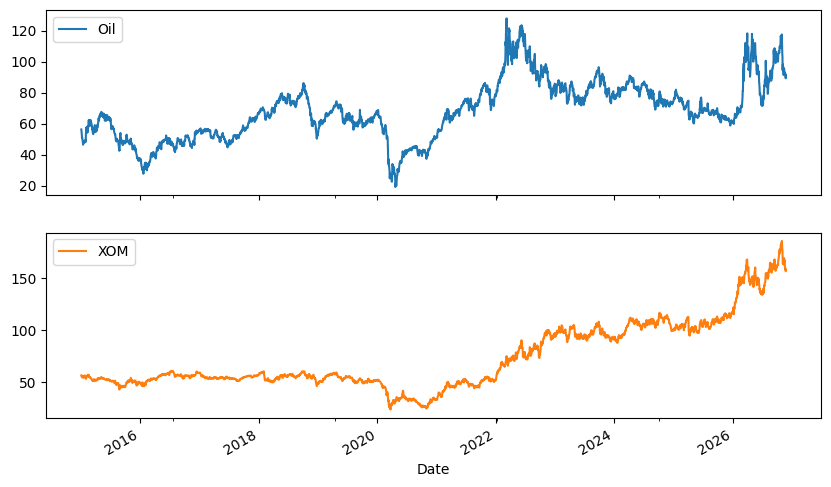

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

data = yf.download(["XOM", "BZ=F"], start="2015-01-01", end="2026-11-25", auto_adjust=True)["Close"]
data.columns = ["Oil", "XOM"]
data = data.dropna()

returns = data.pct_change().dropna()
print(data.tail())
print(returns.corr())

data.plot(subplots=True, figsize=(10, 6))
plt.show()

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

df = returns.copy()
df["XOM_lag1"] = df["XOM"].shift(1)
df["Oil_lag1"] = df["Oil"].shift(1)
df["target"] = df["XOM"].shift(-1)
df = df.dropna()

split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]
features = ["XOM", "Oil", "XOM_lag1", "Oil_lag1"]

model = LinearRegression().fit(train[features], train["target"])
pred = model.predict(test[features])

rmse_model = np.sqrt(mean_squared_error(test["target"], pred))
rmse_zero = np.sqrt(mean_squared_error(test["target"], np.zeros(len(test))))
direction = (np.sign(pred) == np.sign(test["target"])).mean()

print("Model RMSE:", rmse_model)
print("Predict-zero RMSE:", rmse_zero)
print("Direction accuracy:", direction)

Model RMSE: 0.015667805821692495
Predict-zero RMSE: 0.015641595452729896
Direction accuracy: 0.5033444816053512


In [4]:
import numpy as np
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

window = 20
vals = returns[["XOM", "Oil"]].values
split = int(len(vals) * 0.8)

scaler = StandardScaler().fit(vals[:split])
scaled = scaler.transform(vals)

X, y = [], []
for i in range(window, len(scaled)):
    X.append(scaled[i-window:i])
    y.append(vals[i, 0])
X, y = np.array(X), np.array(y)

s = split - window
X_train, X_test = X[:s], X[s:]
y_train, y_test = y[:s], y[s:]

model = keras.Sequential([
    keras.layers.Input(shape=(window, 2)),
    keras.layers.LSTM(32),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.fit(X_train, y_train, epochs=20, batch_size=32,
          validation_split=0.1, verbose=1,
          callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

pred = model.predict(X_test).flatten()
print("LSTM RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("Predict-zero RMSE:", np.sqrt(mean_squared_error(y_test, np.zeros(len(y_test)))))
print("Direction accuracy:", (np.sign(pred) == np.sign(y_test)).mean())

Epoch 1/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0021 - val_loss: 1.8836e-04
Epoch 2/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012 - val_loss: 1.7941e-04
Epoch 3/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0011 - val_loss: 1.7575e-04
Epoch 4/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 9.5597e-04 - val_loss: 1.9545e-04
Epoch 5/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 8.2641e-04 - val_loss: 1.6851e-04
Epoch 6/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 7.8376e-04 - val_loss: 1.8776e-04
Epoch 7/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 6.1185e-04 - val_loss: 1.7490e-04
Epoch 8/20
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 5.4792e-04 - val_loss: 1.8497e-04
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
LSTM RMSE: 0.016149659597630404
Predict-zero RMSE: 0.015641595452729896
Direction accuracy: 0.5250836120401338


In [5]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

v = pd.DataFrame(index=returns.index)
v["xom_vol5"] = returns["XOM"].rolling(5).std()
v["xom_vol20"] = returns["XOM"].rolling(20).std()
v["oil_vol5"] = returns["Oil"].rolling(5).std()
v["oil_vol20"] = returns["Oil"].rolling(20).std()
v["xom_abs"] = returns["XOM"].abs()
v["target"] = returns["XOM"].rolling(5).std().shift(-5)
v = v.dropna()

split = int(len(v) * 0.8)
train, test = v.iloc[:split], v.iloc[split:]
features = ["xom_vol5", "xom_vol20", "oil_vol5", "oil_vol20", "xom_abs"]

naive = test["xom_vol20"]
lin = LinearRegression().fit(train[features], train["target"]).predict(test[features])
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=42)
rf_pred = rf.fit(train[features], train["target"]).predict(test[features])

for name, p in [("Naive (last 20-day vol)", naive), ("Linear", lin), ("Random forest", rf_pred)]:
    print(name, "RMSE:", np.sqrt(mean_squared_error(test["target"], p)), "R2:", r2_score(test["target"], p))

Naive (last 20-day vol) RMSE: 0.006856109740320123 R2: -0.14975715430701775
Linear RMSE: 0.006481785942751018 R2: -0.027637559539719803
Random forest RMSE: 0.006894917117970555 R2: -0.16280984441091473


In [6]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

r = returns
v = pd.DataFrame(index=r.index)
v["xom_vol5"] = np.log(r["XOM"].rolling(5).std())
v["xom_vol20"] = np.log(r["XOM"].rolling(20).std())
v["xom_vol60"] = np.log(r["XOM"].rolling(60).std())
v["oil_vol20"] = np.log(r["Oil"].rolling(20).std())
v["target"] = np.log(r["XOM"].rolling(20).std().shift(-20))
v = v.replace([np.inf, -np.inf], np.nan).dropna()

split = int(len(v) * 0.8)
train, test = v.iloc[:split], v.iloc[split:]
features = ["xom_vol5", "xom_vol20", "xom_vol60", "oil_vol20"]

naive = test["xom_vol20"]
lin = LinearRegression().fit(train[features], train["target"]).predict(test[features])
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=30, random_state=42)
rf_pred = rf.fit(train[features], train["target"]).predict(test[features])

for name, p in [("Naive", naive), ("Linear", lin), ("Random forest", rf_pred)]:
    print(name, "RMSE:", np.sqrt(mean_squared_error(test["target"], p)), "R2:", r2_score(test["target"], p))

Naive RMSE: 0.29253937157549736 R2: -0.3183970455308631
Linear RMSE: 0.2588634254913437 R2: -0.032330979766730605
Random forest RMSE: 0.3247295126398986 R2: -0.6245051570075524


In [7]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

start = int(len(v) * 0.8)
step, gap = 21, 20
preds = {"Naive": [], "Hist mean": [], "Linear": [], "Random forest": []}
actual = []

for t in range(start, len(v), step):
    train = v.iloc[:t - gap]
    test = v.iloc[t:t + step]
    lin = LinearRegression().fit(train[features], train["target"])
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=30, random_state=42, n_jobs=-1)
    rf.fit(train[features], train["target"])
    preds["Naive"].extend(test["xom_vol20"])
    preds["Hist mean"].extend([train["target"].mean()] * len(test))
    preds["Linear"].extend(lin.predict(test[features]))
    preds["Random forest"].extend(rf.predict(test[features]))
    actual.extend(test["target"])

actual = np.array(actual)
base = np.array(preds["Hist mean"])
for name, p in preds.items():
    p = np.array(p)
    rmse = np.sqrt(np.mean((actual - p) ** 2))
    oos_r2 = 1 - np.sum((actual - p) ** 2) / np.sum((actual - base) ** 2)
    print(f"{name}: RMSE {rmse:.4f}, OOS R2 vs hist mean {oos_r2:.4f}")

Naive: RMSE 0.2925, OOS R2 vs hist mean -0.2458
Hist mean: RMSE 0.2621, OOS R2 vs hist mean 0.0000
Linear: RMSE 0.2598, OOS R2 vs hist mean 0.0177
Random forest: RMSE 0.3125, OOS R2 vs hist mean -0.4217


In [8]:
import numpy as np
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

idx = yf.download(["^VIX", "^OVX"], start="2015-01-01", end="2026-11-25", auto_adjust=True)["Close"]
idx.columns = ["OVX", "VIX"]

v2 = v.join(np.log(idx), how="inner").dropna()
v2["vix_chg"] = v2["VIX"].diff(5)
v2 = v2.dropna()

feature_sets = {
    "Linear (old features)": features,
    "Linear + VIX/OVX": features + ["VIX", "OVX", "vix_chg"],
}

start = int(len(v2) * 0.8)
step, gap = 21, 20
results = {k: [] for k in ["Hist mean", *feature_sets, "Random forest + VIX/OVX"]}
actual = []

for t in range(start, len(v2), step):
    train, test = v2.iloc[:t - gap], v2.iloc[t:t + step]
    results["Hist mean"].extend([train["target"].mean()] * len(test))
    for name, f in feature_sets.items():
        m = LinearRegression().fit(train[f], train["target"])
        results[name].extend(m.predict(test[f]))
    f_all = feature_sets["Linear + VIX/OVX"]
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=30, random_state=42, n_jobs=-1)
    results["Random forest + VIX/OVX"].extend(rf.fit(train[f_all], train["target"]).predict(test[f_all]))
    actual.extend(test["target"])

actual = np.array(actual)
base = np.array(results["Hist mean"])
for name, p in results.items():
    p = np.array(p)
    rmse = np.sqrt(np.mean((actual - p) ** 2))
    r2 = 1 - np.sum((actual - p) ** 2) / np.sum((actual - base) ** 2)
    print(f"{name}: RMSE {rmse:.4f}, OOS R2 {r2:.4f}")


[*********************100%***********************]  2 of 2 completed


Hist mean: RMSE 0.2621, OOS R2 0.0000
Linear (old features): RMSE 0.2598, OOS R2 0.0176
Linear + VIX/OVX: RMSE 0.2546, OOS R2 0.0568
Random forest + VIX/OVX: RMSE 0.3026, OOS R2 -0.3324


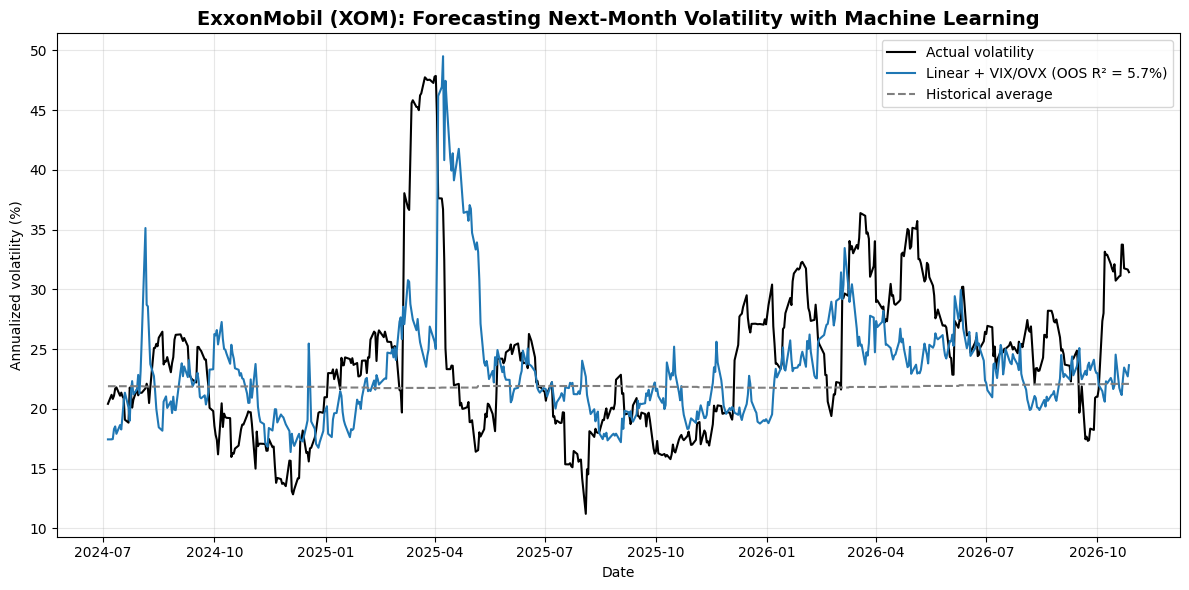

In [9]:
import matplotlib.pyplot as plt
import numpy as np

dates = v2.index[start:start + len(actual)]
to_pct = lambda x: np.exp(np.array(x)) * np.sqrt(252) * 100

plt.figure(figsize=(12, 6))
plt.plot(dates, to_pct(actual), label="Actual volatility", color="black", linewidth=1.5)
plt.plot(dates, to_pct(results["Linear + VIX/OVX"]), label="Linear + VIX/OVX (OOS R² = 5.7%)", color="tab:blue")
plt.plot(dates, to_pct(results["Hist mean"]), label="Historical average", color="tab:gray", linestyle="--")

plt.title("ExxonMobil (XOM): Forecasting Next-Month Volatility with Machine Learning", fontsize=14, fontweight="bold")
plt.ylabel("Annualized volatility (%)")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("xom_volatility_forecast.png", dpi=200)
plt.show()